# Pump availability forecast

Two forecasts from a daily series of available hours (0-24):

1. **Tomorrow**: hours available, plus the probability of a full 24h day and of an outage day.
2. **Next month**: average daily availability with an uncertainty range, from a Markov-chain simulation.

Only `pandas`, `numpy`, `scikit-learn` and `matplotlib` are needed.
Every model is judged by **walk-forward validation** against simple baselines.
If a model cannot beat the baselines, use the baseline.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import brier_score_loss, mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

CSV_PATH = "pump_aval.csv"
SEED = 42
rng = np.random.default_rng(SEED)

## 1. Load and check the data

In [2]:
raw = pd.read_csv(CSV_PATH, encoding="utf-8-sig")  # utf-8-sig strips the BOM in the header
raw["Date"] = pd.to_datetime(raw["Date"], format="%d/%m/%Y")  # dates are DD/MM/YYYY
raw = raw.sort_values("Date").drop_duplicates("Date").set_index("Date")
raw.head()

,Availability
Date,
2026-01-01,24.0
2026-01-02,24.0
2026-01-03,24.0
2026-01-04,24.0
2026-01-05,24.0


In [3]:
y = raw["Availability"].astype(float).clip(0, 24)


In [4]:
y.head()

Date
2026-01-01    24.0
2026-01-02    24.0
2026-01-03    24.0
2026-01-04    24.0
2026-01-05    24.0
Name: Availability, dtype: float64

In [5]:
y.index.min()

Timestamp('2026-01-01 00:00:00')

In [6]:
y.index.max()

Timestamp('2026-11-15 00:00:00')

In [7]:
full_idx = pd.date_range(y.index.min(), y.index.max(), freq="D")

In [8]:
full_idx

DatetimeIndex(['2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04',
               '2026-01-05', '2026-01-06', '2026-01-07', '2026-01-08',
               '2026-01-09', '2026-01-10',
               ...
               '2026-11-06', '2026-11-07', '2026-11-08', '2026-11-09',
               '2026-11-10', '2026-11-11', '2026-11-12', '2026-11-13',
               '2026-11-14', '2026-11-15'],
              dtype='datetime64[us]', length=319, freq='D')

In [9]:
full_idx.difference(y.index)

DatetimeIndex([], dtype='datetime64[us]', freq='D')

In [10]:

print("Missing dates:", len(full_idx.difference(y.index)))
y = y.reindex(full_idx).ffill()  # no-op if there are no gaps
y.index.name = "Date"

Missing dates: 0


In [11]:
LAST_DATE = y.index[-1]
TODAY = LAST_DATE + pd.Timedelta(days=1)  # data runs to yesterday
TOMORROW = TODAY + pd.Timedelta(days=1)
H = (TOMORROW - LAST_DATE).days  # tomorrow is H days after the last observation (2)

print(f"{len(y)} days: {y.index[0].date()} to {LAST_DATE.date()}")
print(f"Forecasting {TOMORROW.date()} -> {H} days after the last observation")
print(f"Full 24h days: {(y == 24).mean():.1%} | partial: {((y > 0) & (y < 24)).mean():.1%} | zero: {(y == 0).mean():.1%}")
print(f"Mean availability: {y.mean():.2f} h/day ({y.mean() / 24:.1%})")
print("\nMonthly mean hours/day:")
print(y.resample("MS").mean().round(1).to_string())

319 days: 2026-01-01 to 2026-11-15
Forecasting 2026-11-17 -> 2 days after the last observation
Full 24h days: 78.7% | partial: 6.9% | zero: 14.4%
Mean availability: 19.77 h/day (82.4%)

Monthly mean hours/day:
Date
2026-01-01    20.9
2026-02-01     3.6
2026-03-01    14.6
2026-04-01    24.0
2026-05-01    24.0
2026-06-01    23.5
2026-07-01    24.0
2026-08-01    20.9
2026-09-01    18.6
2026-10-01    20.1
2026-11-01    24.0
Freq: MS


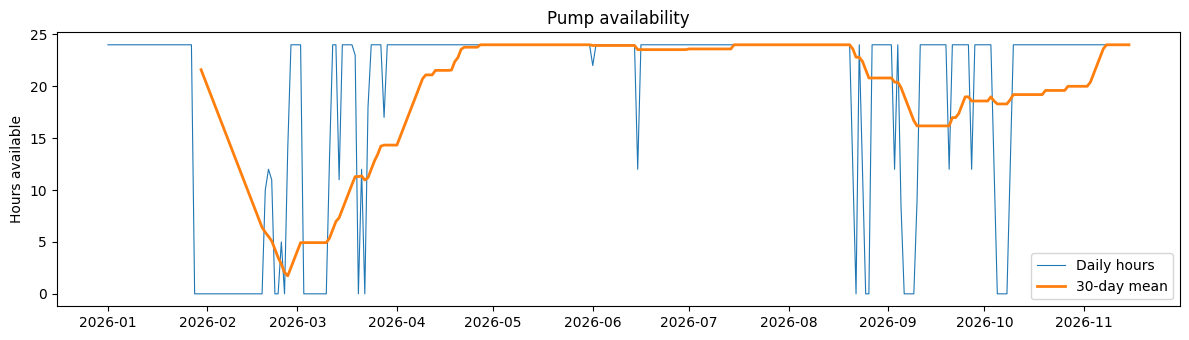

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(y.index, y.values, lw=0.8, label="Daily hours")
ax.plot(y.index, y.rolling(30).mean(), lw=2, label="30-day mean")
ax.set_ylabel("Hours available")
ax.set_title("Pump availability")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Features for the "tomorrow" model

Each row describes the situation at the end of day *t*, using only data up to *t*.
The target is availability on day *t + H* (H = 2 here because today has no data yet).

In [13]:
def days_since(flag, cap=90):
    """Days since flag was last True (0 if True today). Capped when it never happened."""
    out, c = [], cap
    for f in flag.values:
        c = 0 if f else min(c + 1, cap)
        out.append(c)
    return pd.Series(out, index=flag.index)


def make_features(y, h):
    f = pd.DataFrame(index=y.index)
    for k in (0, 1, 2, 6):  # today, yesterday, 2 days ago, 7 days ago
        f[f"lag{k}"] = y.shift(k)
    for w in (3, 7, 30):
        f[f"mean{w}"] = y.rolling(w).mean()
        f[f"min{w}"] = y.rolling(w).min()
    f["frac_full_14"] = (y == 24).rolling(14).mean()
    f["days_since_down"] = days_since(y < 24)  # days since any lost hours
    f["days_since_zero"] = days_since(y == 0)  # days since a total outage
    f["days_since_full"] = days_since(y == 24)  # how long the current problem has lasted
    f["dow_target"] = (f.index + pd.Timedelta(days=h)).dayofweek
    return f


X = make_features(y, H)
FEATURES = list(X.columns)
RIDGE_FEATURES = [c for c in FEATURES if c != "dow_target"]

data = X.copy()
data["target"] = y.shift(-H)
X_now = X.iloc[[-1]]  # features at the last observed day -> used for the live forecast
data = data.dropna()
data["is_full"] = (data["target"] == 24).astype(int)
data["is_outage"] = (data["target"] < 12).astype(int)
print(f"Usable training rows: {len(data)}")

Usable training rows: 288


## 3. Walk-forward validation

Starting from row `START`, refit every `STEP` days on past data only and predict the next block.
Training rows are cut at `i0 - H + 1`, so no target that would still be unknown at forecast time is used.

In [14]:
START, STEP = 150, 7


def walk_forward(make_model, cols, target_col, proba=False):
    out = pd.Series(np.nan, index=data.index)
    for i0 in range(START, len(data), STEP):
        train = data.iloc[: i0 - H + 1]
        test = data.iloc[i0 : i0 + STEP]
        model = make_model().fit(train[cols], train[target_col])
        pred = model.predict_proba(test[cols])[:, 1] if proba else model.predict(test[cols])
        out.iloc[i0 : i0 + STEP] = pred
    return out.iloc[START:]


def ridge():
    return make_pipeline(StandardScaler(), Ridge(alpha=10.0))


def gbr(**kw):
    return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=150,
                                         min_samples_leaf=15, random_state=SEED, **kw)


def gbc():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                          min_samples_leaf=15, random_state=SEED)


test_rows = data.index[START:]
actual = data.loc[test_rows, "target"]

preds = {
    "Baseline: always 24h": pd.Series(24.0, index=test_rows),
    "Baseline: latest day": data.loc[test_rows, "lag0"],
    "Baseline: 7-day mean": data.loc[test_rows, "mean7"],
    "Baseline: 30-day mean": data.loc[test_rows, "mean30"],
    "Ridge": walk_forward(ridge, RIDGE_FEATURES, "target"),
    "Gradient boosting (mean)": walk_forward(gbr, FEATURES, "target"),
    "Gradient boosting (median)": walk_forward(lambda: gbr(loss="quantile", quantile=0.5), FEATURES, "target"),
}
preds = {k: v.clip(0, 24) for k, v in preds.items()}

score = pd.DataFrame({
    "MAE (h)": {k: mean_absolute_error(actual, v) for k, v in preds.items()},
    "RMSE (h)": {k: np.sqrt(mean_squared_error(actual, v)) for k, v in preds.items()},
}).sort_values("MAE (h)")
print(f"Test period: {test_rows[0].date()} to {test_rows[-1].date()} (forecast origins), {len(test_rows)} days")
print(score.round(2).to_string())

Test period: 2026-06-29 to 2026-11-13 (forecast origins), 138 days
                            MAE (h)  RMSE (h)
Baseline: always 24h           2.74      7.52
Baseline: latest day           2.78      7.06
Gradient boosting (median)     2.87      6.88
Gradient boosting (mean)       3.47      6.77
Ridge                          3.64      6.64
Baseline: 7-day mean           4.14      7.91
Baseline: 30-day mean          4.35      7.04


### Probability forecasts
Often more useful than an hours figure, since the pump is usually either fully up or mostly down.
Brier score: lower is better; the prior is the long-run rate.

In [15]:
prob_rows = []
for label, col in [("P(full 24h day)", "is_full"), ("P(outage, <12h)", "is_outage")]:
    p_model = walk_forward(gbc, FEATURES, col, proba=True)
    p_prior = walk_forward(lambda: DummyClassifier(strategy="prior"), FEATURES, col, proba=True)
    truth = data.loc[test_rows, col]
    prob_rows.append({"event": label,
                      "Brier model": brier_score_loss(truth, p_model),
                      "Brier prior": brier_score_loss(truth, p_prior)})
print(pd.DataFrame(prob_rows).round(3).to_string(index=False))

          event  Brier model  Brier prior
P(full 24h day)        0.116        0.138
P(outage, <12h)        0.101        0.097


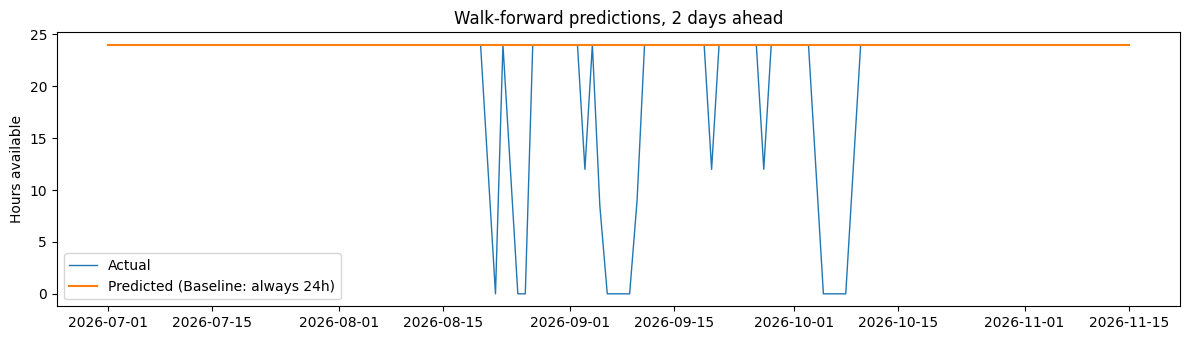

In [16]:
best = score.index[0]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(test_rows + pd.Timedelta(days=H), actual.values, lw=1, label="Actual")
ax.plot(test_rows + pd.Timedelta(days=H), preds[best].values, lw=1.5, label=f"Predicted ({best})")
ax.set_ylabel("Hours available")
ax.set_title(f"Walk-forward predictions, {H} days ahead")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Tomorrow's forecast
Refit on all available data and predict from the last observed day.

In [17]:
cols_of = {"Ridge": RIDGE_FEATURES}
final = {}
final["Ridge"] = ridge().fit(data[RIDGE_FEATURES], data["target"]).predict(X_now[RIDGE_FEATURES])[0]
final["Gradient boosting (mean)"] = gbr().fit(data[FEATURES], data["target"]).predict(X_now[FEATURES])[0]
for q in (0.1, 0.5, 0.9):
    m = gbr(loss="quantile", quantile=q).fit(data[FEATURES], data["target"])
    final[f"Gradient boosting P{int(q * 100)}"] = m.predict(X_now[FEATURES])[0]
final["Baseline: always 24h"] = 24.0
final["Baseline: latest day"] = float(y.iloc[-1])
final["Baseline: 7-day mean"] = float(y.tail(7).mean())
final["Baseline: 30-day mean"] = float(y.tail(30).mean())
final = {k: float(np.clip(v, 0, 24)) for k, v in final.items()}

p_full = gbc().fit(data[FEATURES], data["is_full"]).predict_proba(X_now[FEATURES])[0, 1]
p_out = gbc().fit(data[FEATURES], data["is_outage"]).predict_proba(X_now[FEATURES])[0, 1]

print(f"Forecast for {TOMORROW.date()} (hours available)")
for k, v in final.items():
    print(f"  {k:<28} {v:5.1f}")
print(f"  P(full 24h day)   = {p_full:.1%}")
print(f"  P(outage, <12h)   = {p_out:.1%}")
print(f"\nBest validated approach: {best}  (MAE {score.loc[best, 'MAE (h)']:.2f} h)")

Forecast for 2026-11-17 (hours available)
  Ridge                         23.8
  Gradient boosting (mean)      23.9
  Gradient boosting P10         24.0
  Gradient boosting P50         24.0
  Gradient boosting P90         24.0
  Baseline: always 24h          24.0
  Baseline: latest day          24.0
  Baseline: 7-day mean          24.0
  Baseline: 30-day mean         24.0
  P(full 24h day)   = 99.3%
  P(outage, <12h)   = 0.1%

Best validated approach: Baseline: always 24h  (MAE 2.74 h)


## 5. Next month: Markov-chain simulation

A daily forecast a month out is mostly unknowable, so we forecast the **average over the month** and its spread.
Each day is in one of three states: **full** (24h), **partial** (0-24h) or **zero**.
We estimate day-to-day transition probabilities from history (this captures how outages cluster),
then simulate many futures from the current state.

In [18]:
def state_of(v):
    v = np.asarray(v)
    return np.where(v == 24, 0, np.where(v == 0, 2, 1))


def fit_markov(series, alpha=1.0):
    s = state_of(series.values)
    counts = np.full((3, 3), alpha)  # Laplace smoothing
    for a, b in zip(s[:-1], s[1:]):
        counts[a, b] += 1
    P = counts / counts.sum(axis=1, keepdims=True)
    vals = series.values
    partial = vals[(vals > 0) & (vals < 24)]
    return P, (partial if len(partial) else np.array([12.0]))


def simulate(P, partial, start_state, n_days, n_sims=5000):
    states = np.full(n_sims, start_state)
    out = np.empty((n_sims, n_days))
    for d in range(n_days):
        cum = P[states].cumsum(axis=1)
        states = np.minimum((rng.random(n_sims)[:, None] > cum).sum(axis=1), 2)
        out[:, d] = np.where(states == 0, 24.0, np.where(states == 2, 0.0, rng.choice(partial, n_sims)))
    return out


NEXT_START = TODAY + pd.offsets.MonthBegin(1)  # first day of next month
NEXT_END = NEXT_START + pd.offsets.MonthEnd(0)  # last day of next month
OFF_START = (NEXT_START - LAST_DATE).days
OFF_END = (NEXT_END - LAST_DATE).days
print(f"Target window: {NEXT_START.date()} to {NEXT_END.date()} (days +{OFF_START} to +{OFF_END} after the last observation)")

Target window: 2026-12-01 to 2026-12-31 (days +16 to +46 after the last observation)


### Validate the month-ahead approach
At past origins, predict the mean over the same relative window and compare with simple alternatives.
Windows overlap and there are only a few independent months, so treat this as a sanity check.

In [19]:
MARKOV_WINDOWS = {"Markov (all history)": None, "Markov (last 120d)": 120, "Markov (last 60d)": 60}
rows = []
for t in range(120, len(y) - OFF_END, 7):
    hist = y.iloc[: t + 1]
    truth = y.iloc[t + OFF_START : t + OFF_END + 1].mean()
    row = {"actual": truth}
    for name, win in MARKOV_WINDOWS.items():
        P_, partial_ = fit_markov(hist if win is None else hist.tail(win))
        s_ = simulate(P_, partial_, int(state_of(hist.values[-1:])[0]), OFF_END, n_sims=1000)
        row[name] = s_[:, OFF_START - 1 : OFF_END].mean()
    rows.append({
        **row,
        "Overall mean to date": hist.mean(),
        "Last 30 days": hist.tail(30).mean(),
        "Last 90 days": hist.tail(90).mean(),
        "Always 24h": 24.0,
    })
val = pd.DataFrame(rows)
res = pd.DataFrame({
    "MAE (h/day)": {c: mean_absolute_error(val["actual"], val[c]) for c in val.columns[1:]},
    "RMSE (h/day)": {c: np.sqrt(mean_squared_error(val["actual"], val[c])) for c in val.columns[1:]},
}).sort_values("MAE (h/day)")
print(f"{len(val)} validation origins")
print(res.round(2).to_string())

22 validation origins
                      MAE (h/day)  RMSE (h/day)
Markov (last 60d)            2.44          2.92
Last 30 days                 2.52          3.55
Always 24h                   2.60          3.71
Last 90 days                 3.68          4.47
Overall mean to date         3.76          4.49
Markov (all history)         3.84          4.64
Markov (last 120d)           4.50          5.04


### The forecast

Using: Markov (last 60d)
Transition matrix (rows: today, cols: tomorrow) [full, partial, zero]
          full  partial   zero
full     0.907    0.074  0.019
partial  0.571    0.143  0.286
zero     0.143    0.286  0.571

Forecast for December 2026 (31 days)
  Expected availability: 20.3 h/day (84.6%)
  80% range of the monthly average: 16.3 to 23.6 h/day  (median 20.9)
  Expected total hours: 629 of 744
  Expected full-24h days: 24.6 of 31
  Expected zero-hour days: 3.2
  P(at least one day below 24h): 95.7%
  P(at least one zero-hour day): 74.7%


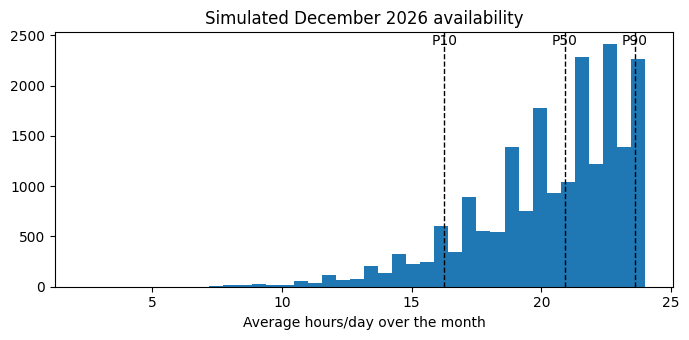

In [20]:
markov_cols = [c for c in res.index if c.startswith("Markov")]
best_markov = markov_cols[0]  # lowest-MAE Markov variant (res is sorted by MAE)
win = MARKOV_WINDOWS[best_markov]
print(f"Using: {best_markov}")
if res.index[0] != best_markov:
    print(f"Note: '{res.index[0]}' scored better than every Markov variant. "
          "Treat the simulation mainly as a guide to the spread, not the centre.")
P, partial = fit_markov(y if win is None else y.tail(win))
print("Transition matrix (rows: today, cols: tomorrow) [full, partial, zero]")
print(pd.DataFrame(P, index=["full", "partial", "zero"], columns=["full", "partial", "zero"]).round(3))

sims = simulate(P, partial, int(state_of(y.values[-1:])[0]), OFF_END, n_sims=20000)
month = sims[:, OFF_START - 1 : OFF_END]  # (n_sims, days in the target month)
month_mean = month.mean(axis=1)
n_days = month.shape[1]
p10, p50, p90 = np.percentile(month_mean, [10, 50, 90])

print(f"\nForecast for {NEXT_START.strftime('%B %Y')} ({n_days} days)")
print(f"  Expected availability: {month_mean.mean():.1f} h/day ({month_mean.mean() / 24:.1%})")
print(f"  80% range of the monthly average: {p10:.1f} to {p90:.1f} h/day  (median {p50:.1f})")
print(f"  Expected total hours: {month_mean.mean() * n_days:.0f} of {24 * n_days}")
print(f"  Expected full-24h days: {(month == 24).sum(axis=1).mean():.1f} of {n_days}")
print(f"  Expected zero-hour days: {(month == 0).sum(axis=1).mean():.1f}")
print(f"  P(at least one day below 24h): {(month < 24).any(axis=1).mean():.1%}")
print(f"  P(at least one zero-hour day): {(month == 0).any(axis=1).mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(month_mean, bins=40)
for v, lab in [(p10, "P10"), (p50, "P50"), (p90, "P90")]:
    ax.axvline(v, color="k", ls="--", lw=1)
    ax.text(v, ax.get_ylim()[1] * 0.95, lab, ha="center")
ax.set_xlabel("Average hours/day over the month")
ax.set_title(f"Simulated {NEXT_START.strftime('%B %Y')} availability")
plt.tight_layout()
plt.show()

## 6. Save a summary

In [21]:
summary = pd.DataFrame([
    {"forecast": f"Tomorrow ({TOMORROW.date()}) hours, {best}", "value": final[best.replace("Gradient boosting (median)", "Gradient boosting P50").replace("Gradient boosting (mean)", "Gradient boosting (mean)")]},
    {"forecast": "Tomorrow P(full 24h)", "value": p_full},
    {"forecast": "Tomorrow P(outage <12h)", "value": p_out},
    {"forecast": f"{NEXT_START.strftime('%B %Y')} mean h/day", "value": month_mean.mean()},
    {"forecast": f"{NEXT_START.strftime('%B %Y')} P10 h/day", "value": p10},
    {"forecast": f"{NEXT_START.strftime('%B %Y')} P90 h/day", "value": p90},
])
summary.to_csv("forecast_summary.csv", index=False)
print(summary.round(2).to_string(index=False))

                                         forecast  value
Tomorrow (2026-11-17) hours, Baseline: always 24h  24.00
                             Tomorrow P(full 24h)   0.99
                          Tomorrow P(outage <12h)   0.00
                         December 2026 mean h/day  20.30
                          December 2026 P10 h/day  16.26
                          December 2026 P90 h/day  23.61


## Notes and next steps
- With ~10 months of data and few failure events, expect baselines to be hard to beat. The validation tables show whether that is true here.
- Add failure and maintenance logs, work orders, or load and operating data. These usually help far more than model tuning.
- Re-run this notebook daily after appending the new row to the CSV; the date logic adjusts automatically.
- If you can install `statsmodels`, `lightgbm` or `prophet`, they are natural next candidates (SARIMA, LightGBM) to benchmark in the same walk-forward loop.